# Advanced Matplotlib for Data Science

**Prepared by Aman Sah — Data Scientist · NLP Engineer**

This notebook moves from core plotting patterns to advanced 2D, field-based, and 3D visualizations. It is designed for classroom teaching: read the explanation, run the cell, inspect the figure, and answer the interpretation questions.

**Learning outcomes**
- Select a chart that matches a data question.
- Build scatter plots, bar charts, filled regions, contour maps, pseudocolor maps, and 3D plots.
- Format ticks, labels, legends, colorbars, annotations, and layouts.
- Load public data from GitHub and request current weather observations/forecasts from a public API.
- Understand when 3D and dense visualizations help—and when they make interpretation harder.

> **Data note:** The notebook retrieves data from the internet when its download cells run. Network access may be restricted in some classroom/Jupyter environments. A fallback synthetic dataset is included for the weather example. Public API availability, rate limits, and dataset URLs can change; record the retrieval date when using results in a report.

## 0. Setup and plotting workflow

Matplotlib's object-oriented interface (`fig, ax = plt.subplots()`) is recommended for complex figures because each axes can be controlled independently. `pyplot` remains useful for quick exploration.

**Install if needed:** `pip install matplotlib numpy pandas requests scikit-learn`

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, AutoMinorLocator, FuncFormatter, PercentFormatter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import requests
from io import StringIO

print("Python:", sys.version.split()[0])
print("Matplotlib:", matplotlib.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

# A consistent, readable style for the teaching notebook.
plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "figure.dpi": 110,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "legend.frameon": True,
    "axes.grid": True,
    "grid.alpha": 0.25,
})


Python: 3.14.6
Matplotlib: 3.11.0
NumPy: 2.4.4
Pandas: 3.0.3


## 1. Fetch a real public dataset: Palmer Penguins (GitHub)

**Problem statement:** Can body measurements help us distinguish penguin species? We will use the Palmer Penguins dataset maintained on GitHub. It is observational ecological data, not fabricated classroom data.

Source: [Palmer Penguins project on GitHub](https://github.com/allisonhorst/palmerpenguins). The CSV URL below is a public raw file. The data are downloaded when the cell runs.

In [2]:
PENGUINS_URL = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"

try:
    penguins = pd.read_csv(PENGUINS_URL)
    print("Downloaded Palmer Penguins dataset.")
except Exception as exc:
    print("Could not download dataset:", repr(exc))
    print("Use a network-enabled notebook session and retry this cell.")
    raise

Downloaded Palmer Penguins dataset.


In [3]:
penguins

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
...,...,...,...,...,...,...,...,...
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009


In [4]:
penguins.columns

Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex', 'year'],
      dtype='str')

In [5]:
penguins.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


In [7]:
penguins[penguins.isnull()]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
339,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
340,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
341,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
342,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:


display(penguins.head())
print("Shape:", penguins.shape)
print("\\nMissing values per column:")
display(penguins.isna().sum().to_frame("missing_count"))


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


Shape: (344, 8)
\nMissing values per column:


,missing_count
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11
year,0


### 1.1 Clean the data before plotting

Missing measurements can cause gaps or errors in some charts. For the examples below, create a clean subset with the variables we need. Keep the original `penguins` DataFrame unchanged so students can compare before and after cleaning.

In [9]:
plot_df = penguins.dropna(subset=[
    "species", "island", "bill_length_mm", "bill_depth_mm",
    "flipper_length_mm", "body_mass_g", "sex"
]).copy()

print("Rows before cleaning:", len(penguins))
print("Rows used for measurement plots:", len(plot_df))
display(plot_df.describe().round(2))


Rows before cleaning: 344
Rows used for measurement plots: 333


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,333.00,333.00,333.00,333.00,333.00
mean,43.99,17.16,200.97,4207.06,2008.04
std,5.47,1.97,14.02,805.22,0.81
min,32.10,13.10,172.00,2700.00,2007.00
25%,39.50,15.60,190.00,3550.00,2007.00
50%,44.50,17.30,197.00,4050.00,2008.00
75%,48.60,18.70,213.00,4775.00,2009.00
max,59.60,21.50,231.00,6300.00,2009.00


In [12]:
plot_df['species'].unique()

<StringArray>
['Adelie', 'Gentoo', 'Chinstrap']
Length: 3, dtype: str

In [15]:
plot_df.groupby('species')['bill_length_mm'].mean()

species
Adelie       38.823973
Chinstrap    48.833824
Gentoo       47.568067
Name: bill_length_mm, dtype: float64

In [16]:
plot_df.groupby('species')['bill_length_mm'].sum()

species
Adelie       5668.3
Chinstrap    3320.7
Gentoo       5660.6
Name: bill_length_mm, dtype: float64

## 2. Scatter plots: relationships, groups, and outliers

**Question:** Is bill length associated with bill depth, and does the pattern vary by species?

In a scatter plot, each point is one observation. Color can encode a category; marker size can encode a numeric variable. Avoid encoding too many variables at once because the figure becomes difficult to decode.

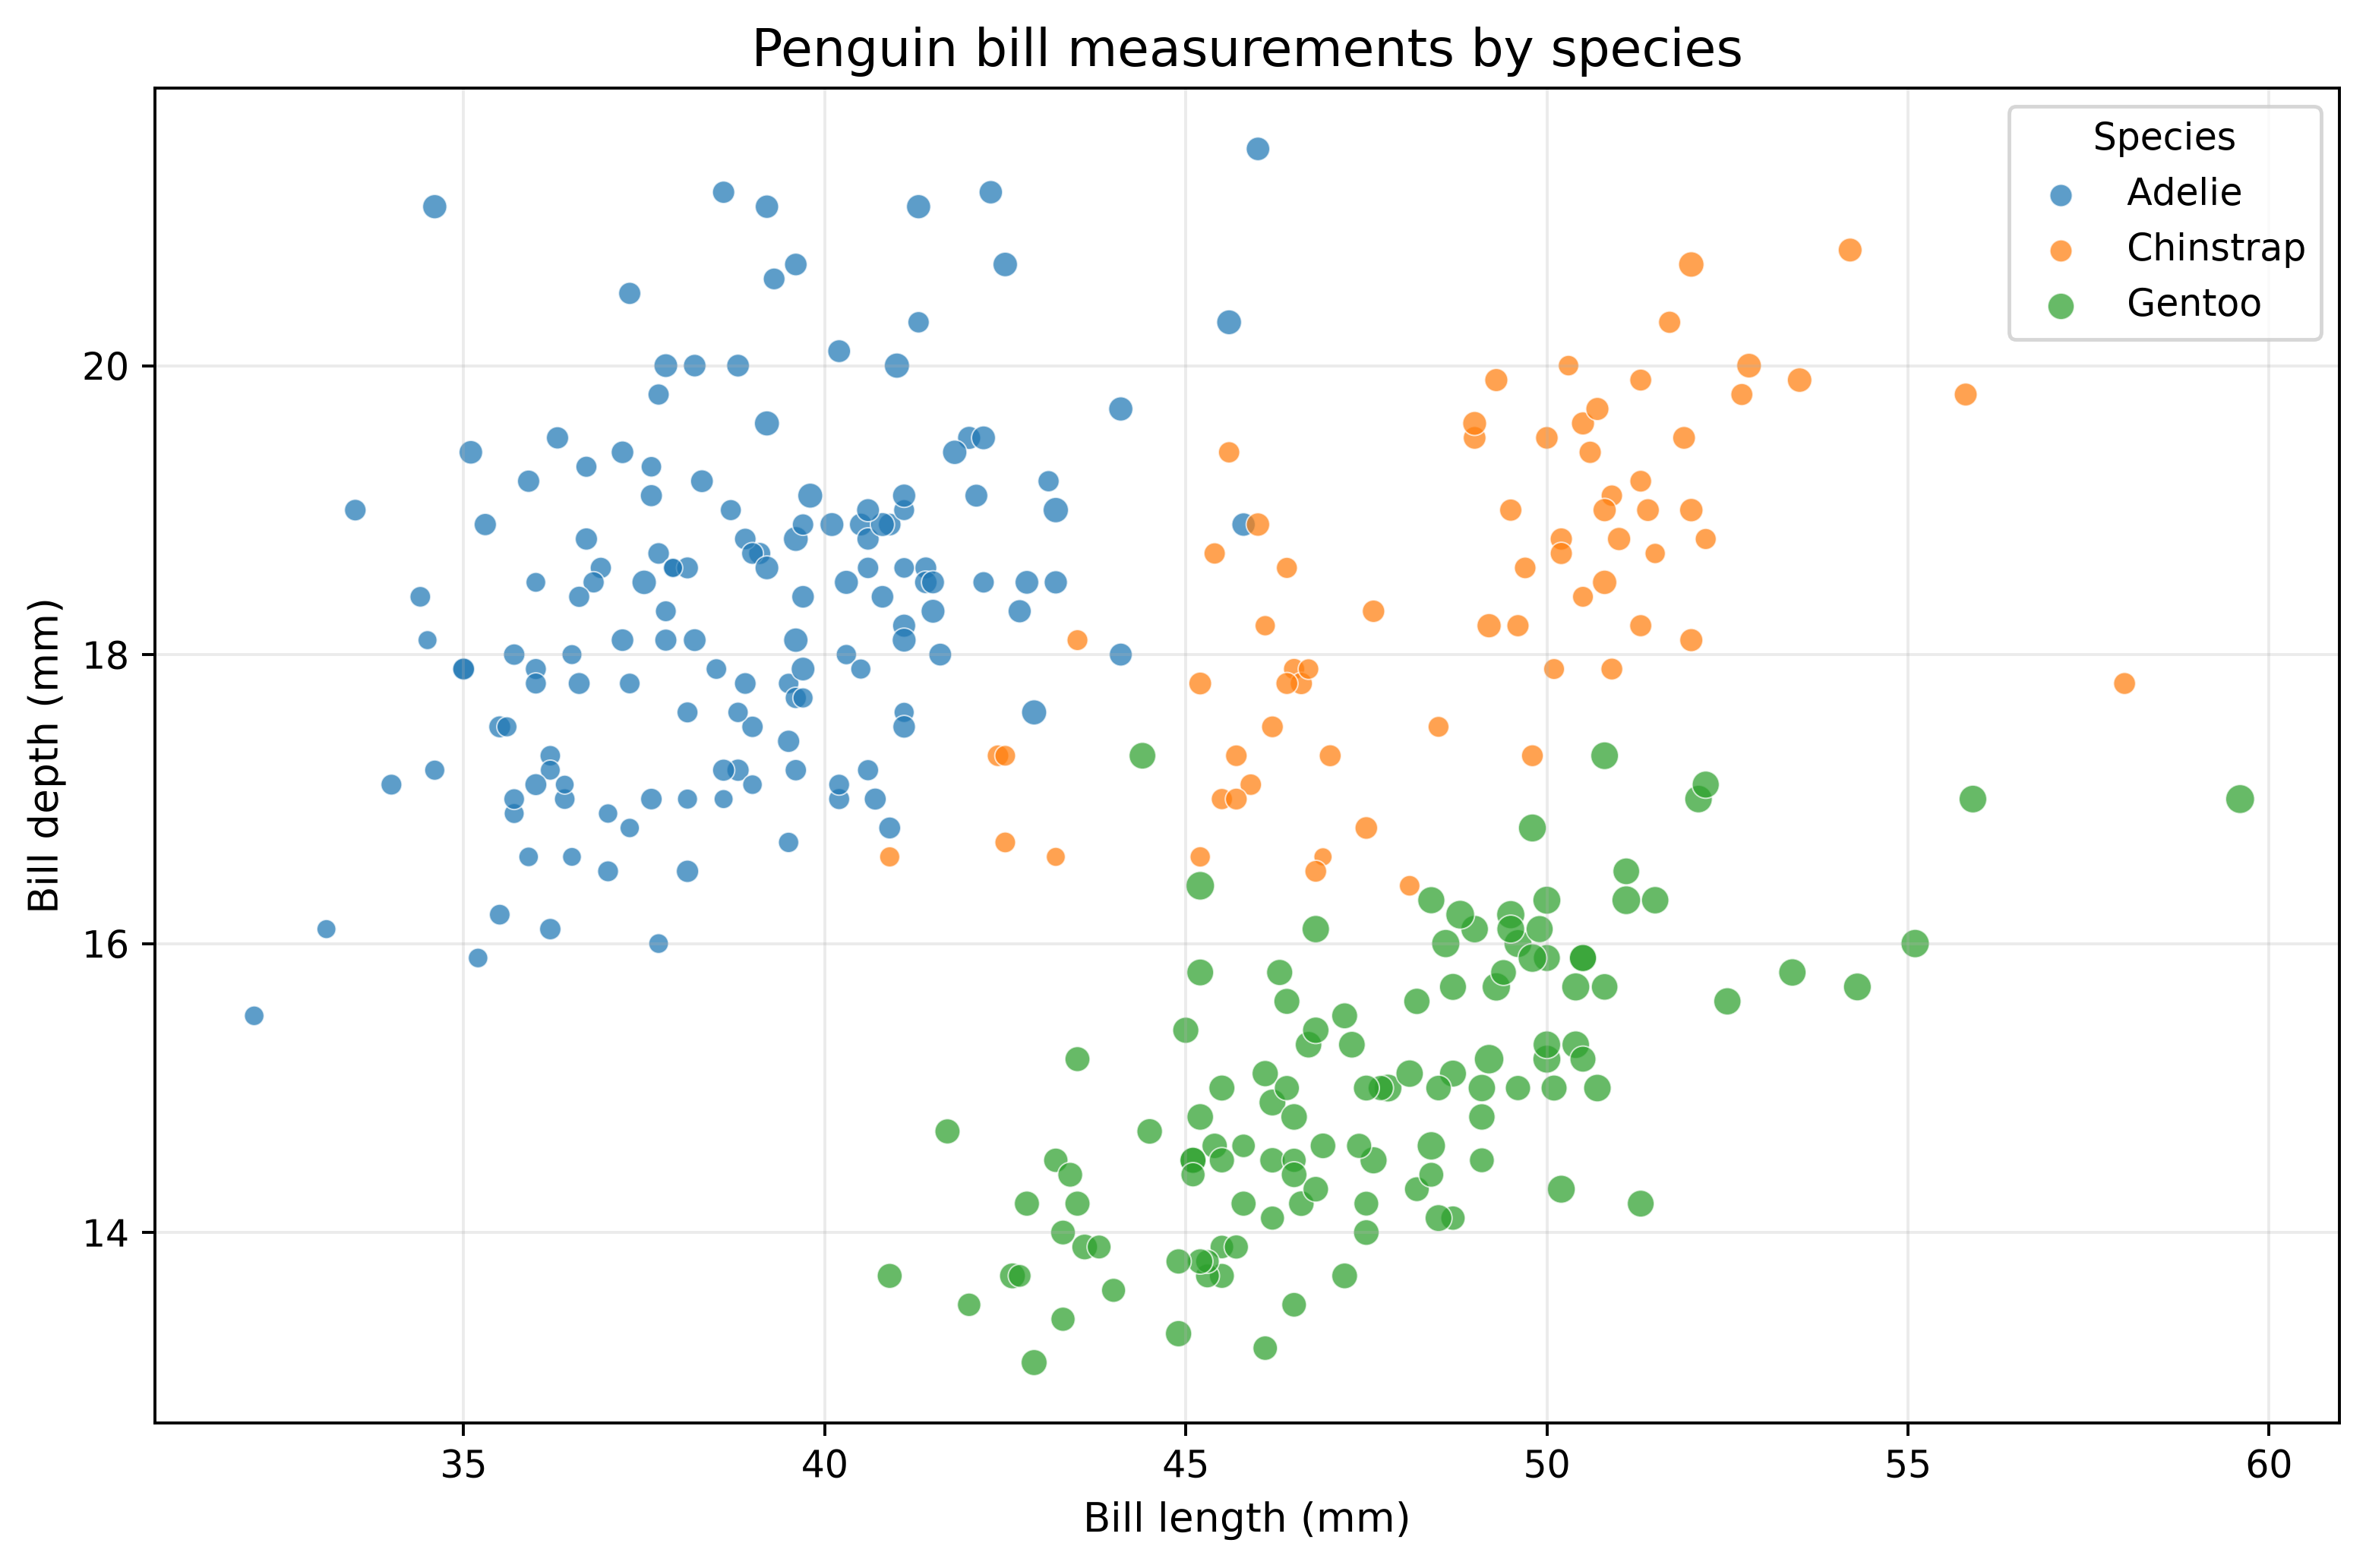

In [17]:
fig, ax = plt.subplots(figsize=(9, 6),dpi=350)

for species, group in plot_df.groupby("species"):
    ax.scatter(
        group["bill_length_mm"], group["bill_depth_mm"],
        s=25 + (group["body_mass_g"] - plot_df["body_mass_g"].min()) / 90,
        alpha=0.72, edgecolor="white", linewidth=0.4, label=species
    )

ax.set(
    title="Penguin bill measurements by species",
    xlabel="Bill length (mm)",
    ylabel="Bill depth (mm)"
)
ax.legend(title="Species")
ax.grid(True, alpha=0.25)
fig.tight_layout()
plt.show()


### 2.1 Add a trend line and annotate an observation

A simple least-squares line can summarize the overall linear trend. It does **not** prove causation, and it may hide species-specific patterns. Here we also label the point with the longest bill in the cleaned data.

In [21]:
x = plot_df["bill_length_mm"].to_numpy()
y = plot_df["bill_depth_mm"].to_numpy()
slope, intercept = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), len(x))


x_line

array([32.1       , 32.18283133, 32.26566265, 32.34849398, 32.4313253 ,
       32.51415663, 32.59698795, 32.67981928, 32.7626506 , 32.84548193,
       32.92831325, 33.01114458, 33.0939759 , 33.17680723, 33.25963855,
       33.34246988, 33.4253012 , 33.50813253, 33.59096386, 33.67379518,
       33.75662651, 33.83945783, 33.92228916, 34.00512048, 34.08795181,
       34.17078313, 34.25361446, 34.33644578, 34.41927711, 34.50210843,
       34.58493976, 34.66777108, 34.75060241, 34.83343373, 34.91626506,
       34.99909639, 35.08192771, 35.16475904, 35.24759036, 35.33042169,
       35.41325301, 35.49608434, 35.57891566, 35.66174699, 35.74457831,
       35.82740964, 35.91024096, 35.99307229, 36.07590361, 36.15873494,
       36.24156627, 36.32439759, 36.40722892, 36.49006024, 36.57289157,
       36.65572289, 36.73855422, 36.82138554, 36.90421687, 36.98704819,
       37.06987952, 37.15271084, 37.23554217, 37.31837349, 37.40120482,
       37.48403614, 37.56686747, 37.6496988 , 37.73253012, 37.81

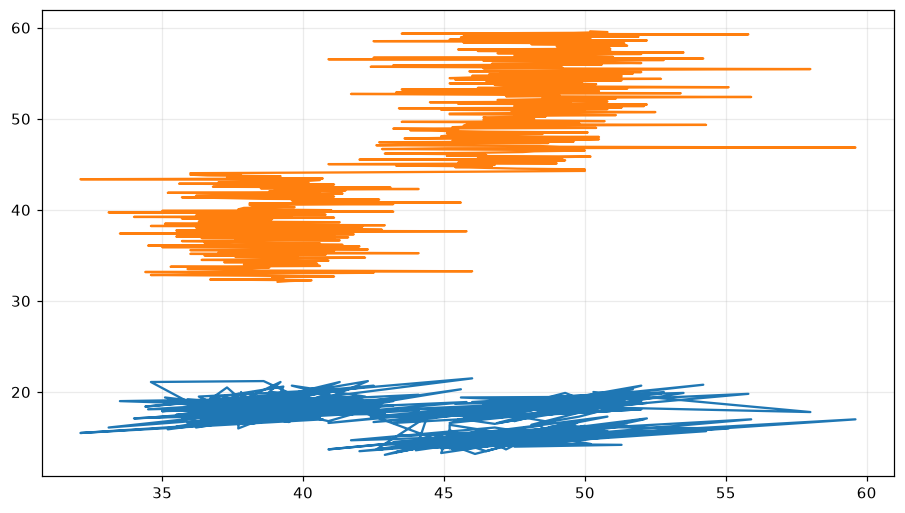

In [23]:
plt.plot(x,y);
plt.plot(x,x_line)

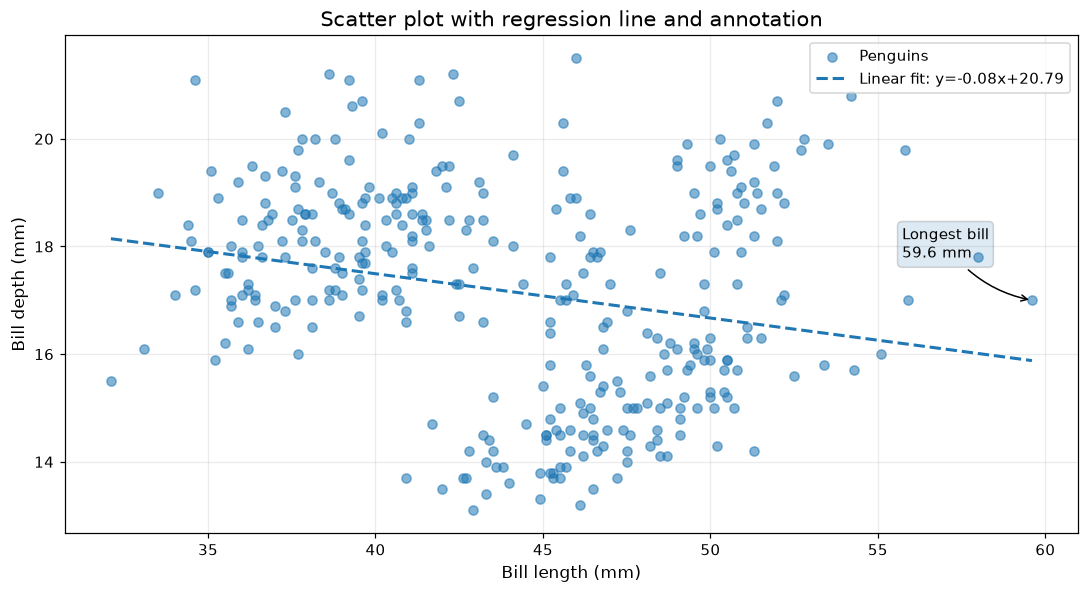

In [24]:

fig, ax = plt.subplots()
ax.scatter(x, y, alpha=0.55, label="Penguins")
ax.plot(x_line, slope * x_line + intercept, linestyle="--",
        linewidth=2, label=f"Linear fit: y={slope:.2f}x+{intercept:.2f}")

row = plot_df.loc[plot_df["bill_length_mm"].idxmax()]
ax.annotate(
    f"Longest bill\n{row['bill_length_mm']:.1f} mm",
    xy=(row["bill_length_mm"], row["bill_depth_mm"]),
    xytext=(-85, 28), textcoords="offset points",
    arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0.2"),
    bbox=dict(boxstyle="round,pad=0.3", alpha=0.15)
)
ax.set(title="Scatter plot with regression line and annotation",
       xlabel="Bill length (mm)", ylabel="Bill depth (mm)")
ax.legend()
fig.tight_layout()
plt.show()


## 3. Bar plots: compare categories correctly

**Question:** How many cleaned observations are available for each species?

Bars are useful for comparing categories. For means or rates, show the unit and consider uncertainty. A bar chart should normally start at zero because bar length encodes magnitude.

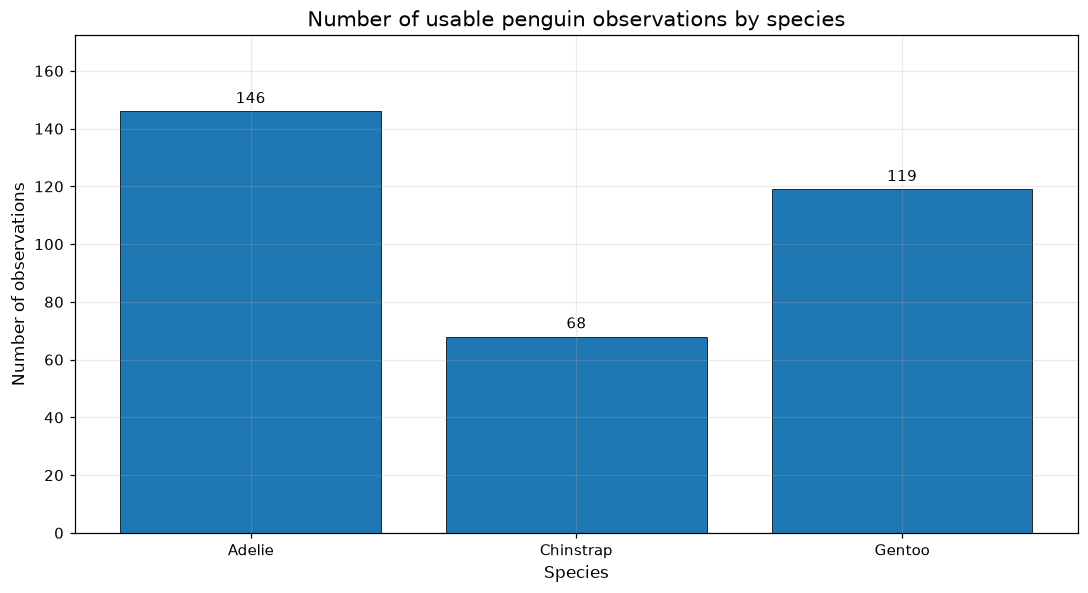

In [25]:
species_counts = plot_df["species"].value_counts().sort_index()

fig, ax = plt.subplots()
bars = ax.bar(species_counts.index, species_counts.values, edgecolor="black", linewidth=0.5)
ax.bar_label(bars, padding=3, fmt="%d")
ax.set(title="Number of usable penguin observations by species",
       xlabel="Species", ylabel="Number of observations")
ax.set_ylim(0, species_counts.max() * 1.18)
fig.tight_layout()
plt.show()


### 3.1 Grouped bars: compare a statistic across two categories

This plot compares mean body mass by species and sex. A grouped bar chart makes the comparisons side-by-side. It can be useful to add confidence intervals in a more advanced analysis; the standard deviation shown here describes spread, not uncertainty in the mean.

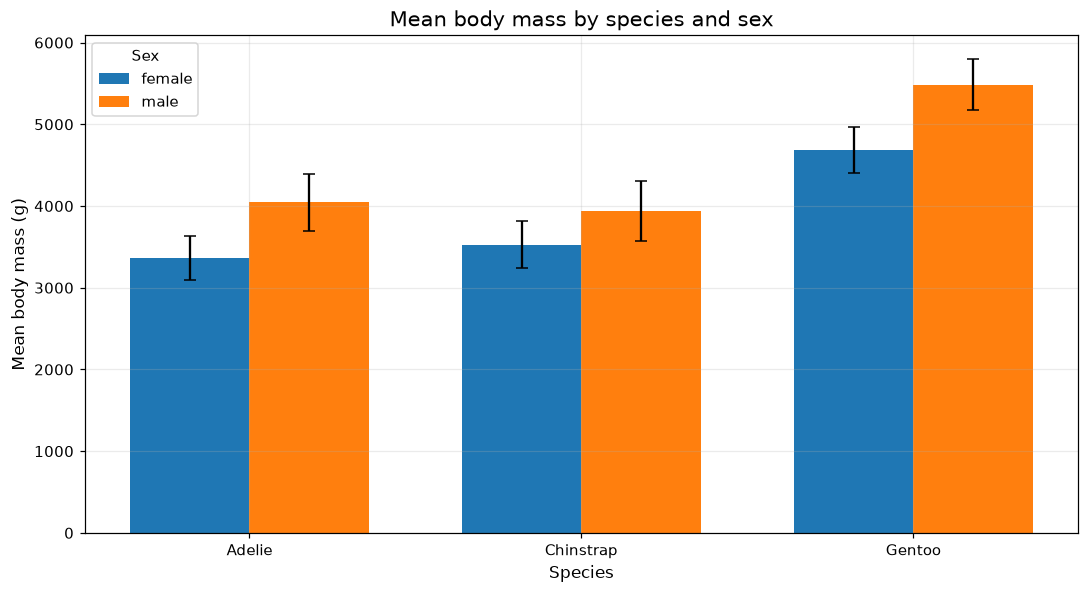

In [26]:
group_stats = (
    plot_df.groupby(["species", "sex"], observed=True)["body_mass_g"]
    .agg(["mean", "std", "count"]).reset_index()
)
means = group_stats.pivot(index="species", columns="sex", values="mean")
stds = group_stats.pivot(index="species", columns="sex", values="std")

species = means.index.to_list()
sexes = means.columns.to_list()
xpos = np.arange(len(species))
width = 0.36

fig, ax = plt.subplots()
for i, sex in enumerate(sexes):
    offset = (i - (len(sexes)-1)/2) * width
    vals = means[sex].to_numpy()
    errs = stds[sex].to_numpy()
    ax.bar(xpos + offset, vals, width, yerr=errs, capsize=4, label=sex)

ax.set_xticks(xpos, species)
ax.set(title="Mean body mass by species and sex",
       xlabel="Species", ylabel="Mean body mass (g)")
ax.legend(title="Sex")
fig.tight_layout()
plt.show()


## 4. Filled plots: uncertainty, thresholds, and stacked quantities

`fill_between(x, y1, y2)` shades the region between two curves. It is useful for uncertainty bands, operating ranges, or the gap between two measurements. Here we use a transparent synthetic time series so the idea is easy to see.

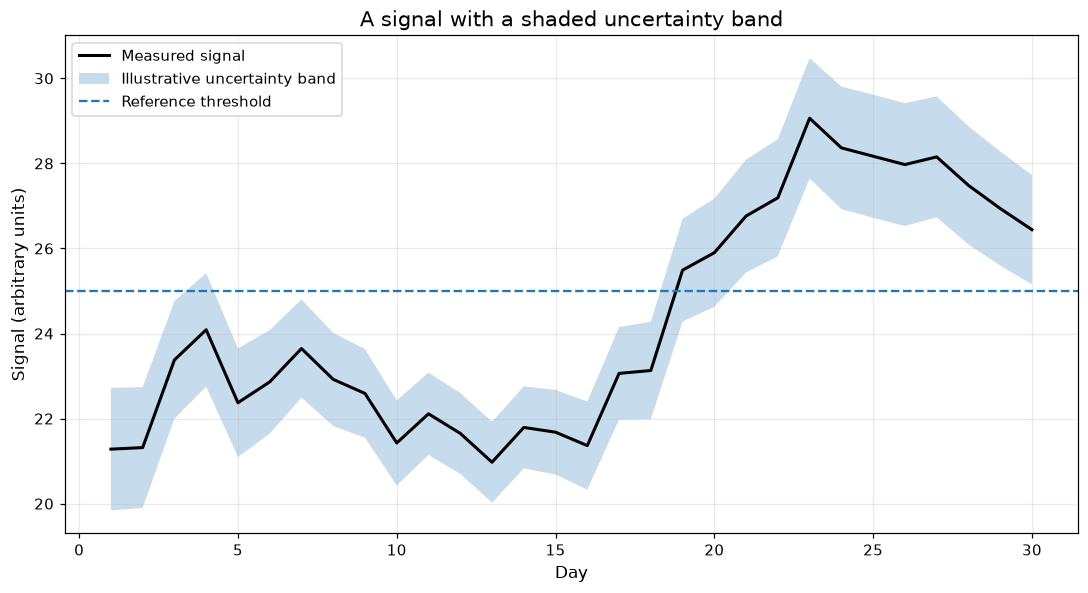

In [27]:
rng = np.random.default_rng(42)
days = np.arange(1, 31)
signal = 20 + 0.25 * days + 2.5 * np.sin(days / 3) + rng.normal(0, 0.7, len(days))
uncertainty = 1.2 + 0.25 * np.cos(days / 4)
lower = signal - uncertainty
upper = signal + uncertainty

fig, ax = plt.subplots()
ax.plot(days, signal, color="black", linewidth=2, label="Measured signal")
ax.fill_between(days, lower, upper, alpha=0.25, label="Illustrative uncertainty band")
ax.axhline(25, linestyle="--", linewidth=1.5, label="Reference threshold")
ax.set(title="A signal with a shaded uncertainty band",
       xlabel="Day", ylabel="Signal (arbitrary units)")
ax.legend()
fig.tight_layout()
plt.show()


### 4.1 Fill only where a condition is true

Use `where=` to shade only periods that exceed a threshold. `interpolate=True` estimates the boundary intersection so the filled region does not abruptly start at the nearest sample.

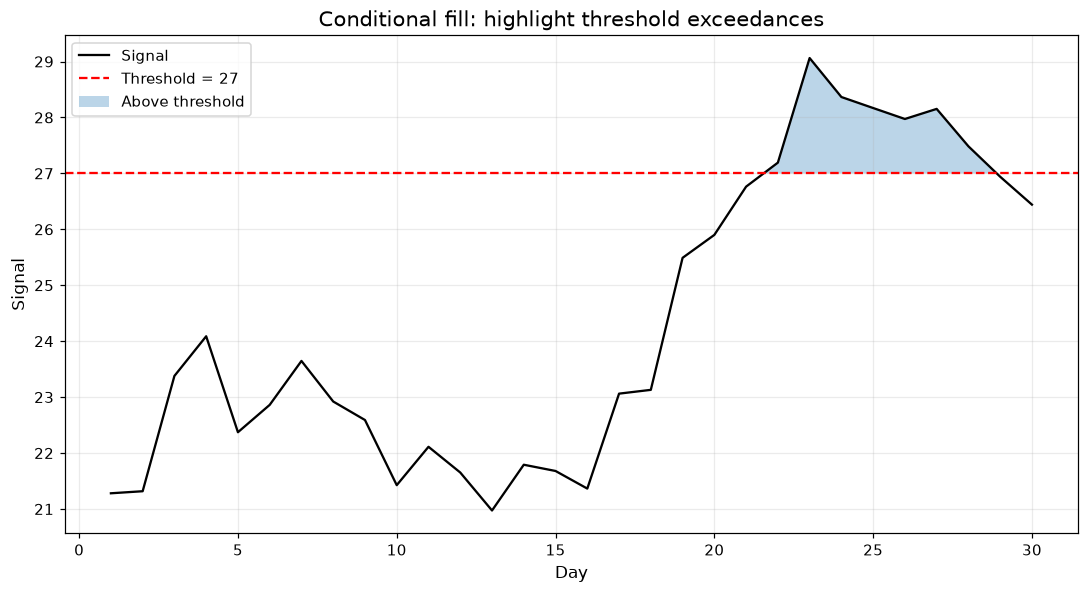

In [28]:
fig, ax = plt.subplots()
ax.plot(days, signal, color="black", label="Signal")
threshold = 27
ax.axhline(threshold, color="red", linestyle="--", label=f"Threshold = {threshold}")
ax.fill_between(
    days, signal, threshold, where=(signal >= threshold),
    interpolate=True, alpha=0.3, label="Above threshold"
)
ax.set(title="Conditional fill: highlight threshold exceedances",
       xlabel="Day", ylabel="Signal")
ax.legend()
fig.tight_layout()
plt.show()


## 5. 2D contour maps: visualize a continuous field

A contour line connects locations with the same value of `Z`. `contourf` fills the regions between levels. These plots are useful for spatial measurements, temperature fields, model loss surfaces, and engineering response maps.

The following field is a **mathematical demonstration**, not measured geographic data. `X` and `Y` are coordinate grids and `Z` contains the field value at each grid location.

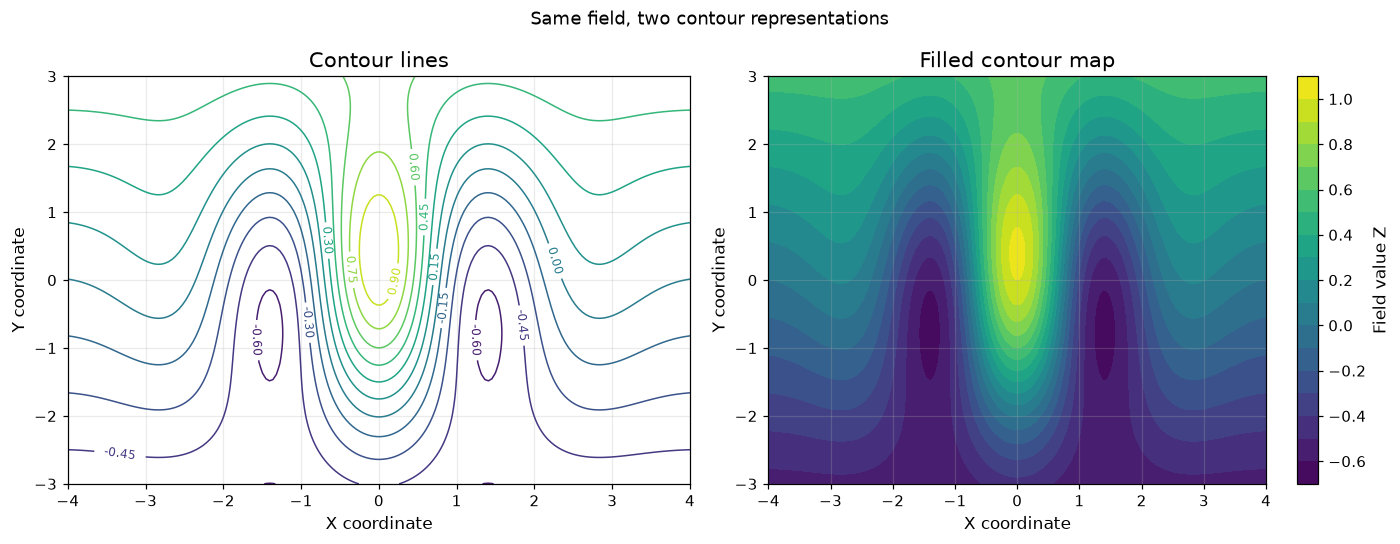

In [29]:
x = np.linspace(-4, 4, 180)
y = np.linspace(-3, 3, 140)
X, Y = np.meshgrid(x, y)
Z = np.exp(-(X**2 + Y**2) / 4) * np.cos(2 * X) + 0.18 * Y

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cs = axes[0].contour(X, Y, Z, levels=14, linewidths=1)
axes[0].clabel(cs, inline=True, fontsize=8, fmt="%.2f")
axes[0].set_title("Contour lines")
axes[0].set_xlabel("X coordinate")
axes[0].set_ylabel("Y coordinate")

cf = axes[1].contourf(X, Y, Z, levels=18, cmap="viridis")
fig.colorbar(cf, ax=axes[1], label="Field value Z")
axes[1].set_title("Filled contour map")
axes[1].set_xlabel("X coordinate")
axes[1].set_ylabel("Y coordinate")

fig.suptitle("Same field, two contour representations")
fig.tight_layout()
plt.show()


### 5.1 How contour levels work

- `levels=10` asks Matplotlib to choose a set of levels; explicit level arrays give exact thresholds.
- `contour` emphasizes boundaries; `contourf` emphasizes regions.
- Add a colorbar when color represents a numeric value.
- Use equal axis scaling when equal distances on x and y should look equal.
- Contours interpolate between grid values. They do not create extra measurement precision.

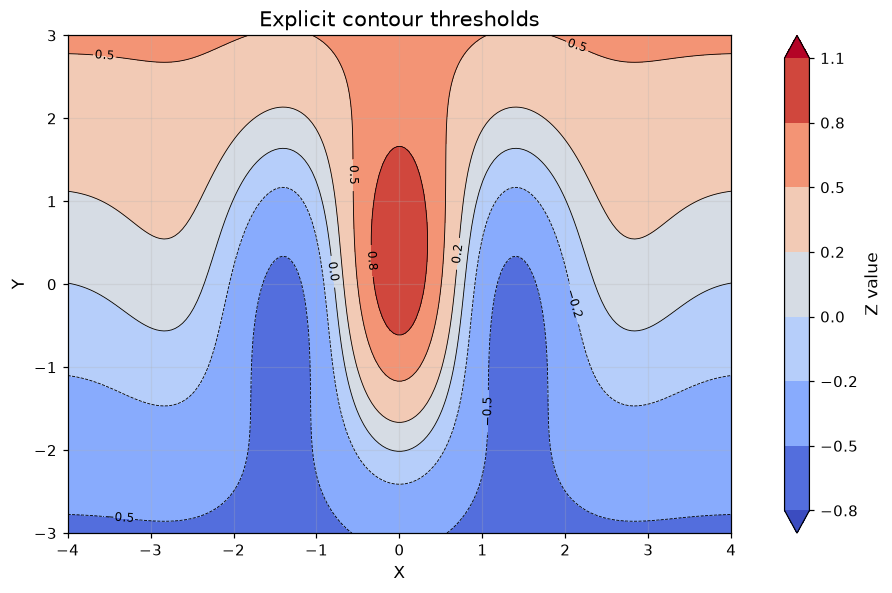

In [30]:
levels = [-0.8, -0.5, -0.2, 0, 0.2, 0.5, 0.8, 1.1]

fig, ax = plt.subplots()
cf = ax.contourf(X, Y, Z, levels=levels, extend="both", cmap="coolwarm")
lines = ax.contour(X, Y, Z, levels=levels, colors="black", linewidths=0.55)
ax.clabel(lines, inline=True, fontsize=8)
fig.colorbar(cf, ax=ax, label="Z value", ticks=levels)
ax.set(title="Explicit contour thresholds", xlabel="X", ylabel="Y")
ax.set_aspect("equal", adjustable="box")
fig.tight_layout()
plt.show()


## 6. Pseudocolor: `pcolor`, `pcolormesh`, and `imshow`

These methods color grid cells rather than draw equal-value curves.
- `pcolormesh` is generally preferred for large rectangular grids and supports non-uniform coordinates efficiently.
- `pcolor` is flexible but often slower for large arrays.
- `imshow` displays a regular 2D raster and is commonly used for images or matrix-like data.

We use the same `Z` field so the methods can be compared directly.

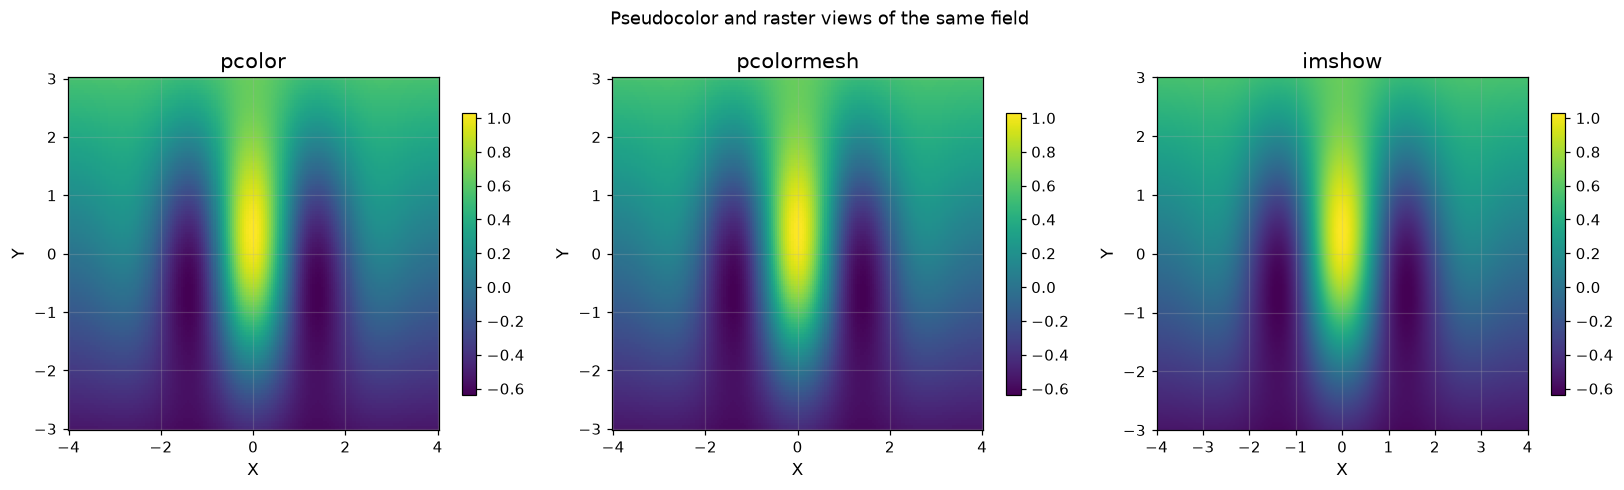

In [31]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

x = np.linspace(-4, 4, 180)
y = np.linspace(-3, 3, 140)
X, Y = np.meshgrid(x, y)
Z = np.exp(-(X**2 + Y**2) / 4) * np.cos(2 * X) + 0.18 * Y

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

m0 = axes[0].pcolor(X, Y, Z, shading="auto", cmap="viridis")
axes[0].set_title("pcolor")
fig.colorbar(m0, ax=axes[0], shrink=0.8)

m1 = axes[1].pcolormesh(X, Y, Z, shading="auto", cmap="viridis")
axes[1].set_title("pcolormesh")
fig.colorbar(m1, ax=axes[1], shrink=0.8)

m2 = axes[2].imshow(
    Z, origin="lower", aspect="auto", cmap="viridis",
    extent=[x.min(), x.max(), y.min(), y.max()]
)
axes[2].set_title("imshow")
fig.colorbar(m2, ax=axes[2], shrink=0.8)

for ax in axes:
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
fig.suptitle("Pseudocolor and raster views of the same field")
fig.tight_layout()
plt.show()


### 6.1 Plot a correlation matrix as a heatmap

This is a practical data-science use case: a correlation matrix is a 2D numerical array. The colorbar helps interpret the strength and sign of each relationship.

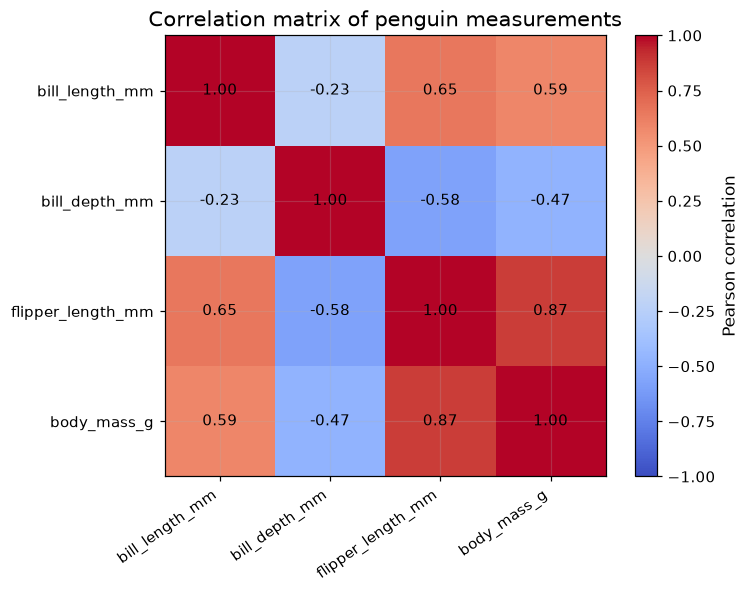

In [32]:
numeric = plot_df[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]]
corr = numeric.corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(np.arange(len(corr.columns)), corr.columns, rotation=35, ha="right")
ax.set_yticks(np.arange(len(corr.index)), corr.index)
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlation matrix of penguin measurements")
fig.tight_layout()
plt.show()


## 7. 3D figures: scatter, surfaces, and wireframes

Matplotlib's `mplot3d` toolkit adds a 3D axes by using `projection="3d"`. It is convenient for teaching and moderate-sized figures, though it is not a high-performance 3D rendering engine. Interactive notebook backends may allow rotation with the mouse.

**Important:** 3D perspective can distort apparent distances and hide points. Consider a 2D view if it communicates the result more clearly.

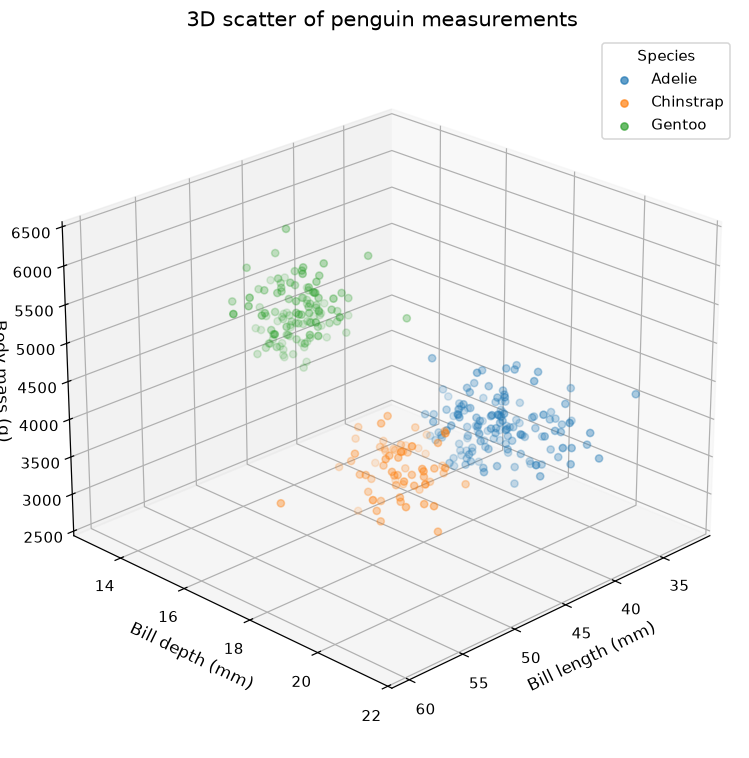

In [33]:
# 3D scatter: each penguin is a point in three measurement dimensions.
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

for species, group in plot_df.groupby("species"):
    ax.scatter(
        group["bill_length_mm"], group["bill_depth_mm"], group["body_mass_g"],
        s=22, alpha=0.7, label=species
    )

ax.set(title="3D scatter of penguin measurements",
       xlabel="Bill length (mm)", ylabel="Bill depth (mm)", zlabel="Body mass (g)")
ax.legend(title="Species")
ax.view_init(elev=24, azim=45)
plt.tight_layout()
plt.show()


### 7.1 3D surface and wireframe

A surface displays the values of `Z=f(X,Y)` as a continuous 3D sheet. A wireframe shows the grid structure and can reveal shape without an opaque surface hiding the back of the field.

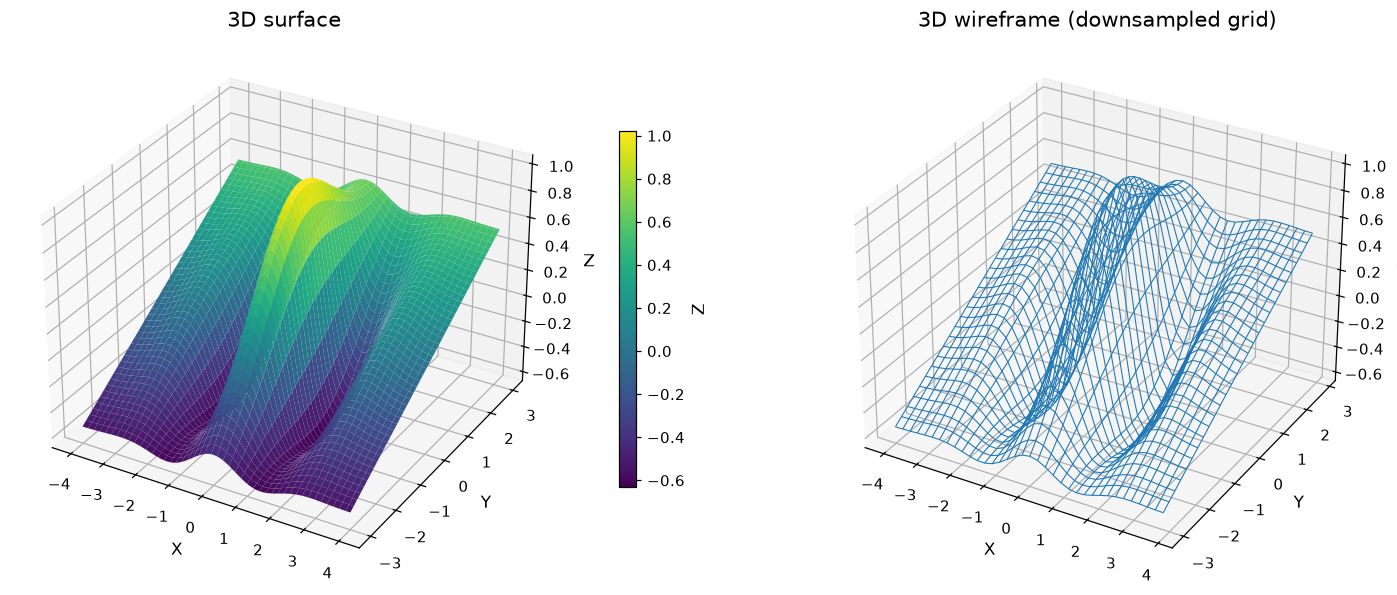

In [34]:
fig = plt.figure(figsize=(14, 5.5))
ax1 = fig.add_subplot(121, projection="3d")
surf = ax1.plot_surface(X, Y, Z, cmap="viridis", edgecolor="none", antialiased=True)
fig.colorbar(surf, ax=ax1, shrink=0.65, pad=0.08, label="Z")
ax1.set_title("3D surface")
ax1.set_xlabel("X"); ax1.set_ylabel("Y"); ax1.set_zlabel("Z")

ax2 = fig.add_subplot(122, projection="3d")
ax2.plot_wireframe(X[::5, ::5], Y[::5, ::5], Z[::5, ::5],
                   rstride=1, cstride=1, linewidth=0.7)
ax2.set_title("3D wireframe (downsampled grid)")
ax2.set_xlabel("X"); ax2.set_ylabel("Y"); ax2.set_zlabel("Z")

fig.tight_layout()
plt.show()


### 7.2 3D contour lines and filled contours projected onto a plane

`Axes3D.contour` and `Axes3D.contourf` can draw contour information at a chosen z-offset. This is often used to project a 2D field onto the floor or side of a 3D surface. The `zdir` argument selects the direction of the projection.

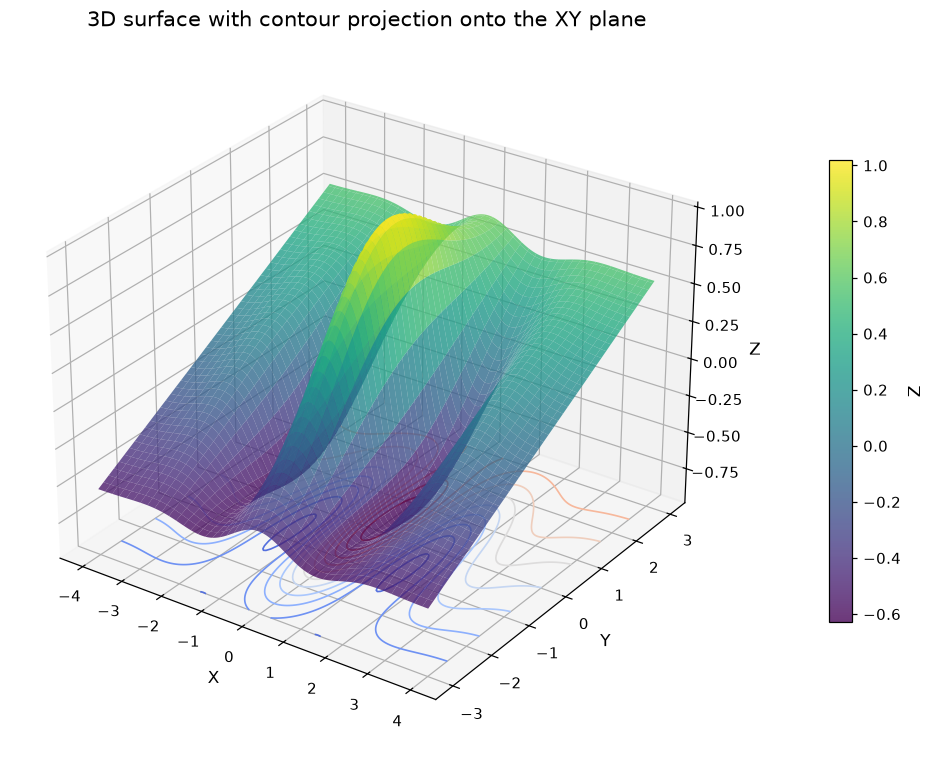

In [35]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

surf = ax.plot_surface(X, Y, Z, cmap="viridis", alpha=0.78, linewidth=0)
z_floor = Z.min() - 0.35
ax.contour(X, Y, Z, zdir="z", offset=z_floor, levels=12,
           cmap="coolwarm", linewidths=1.1)
ax.set_zlim(z_floor, Z.max())
ax.set(title="3D surface with contour projection onto the XY plane",
       xlabel="X", ylabel="Y", zlabel="Z")
fig.colorbar(surf, ax=ax, shrink=0.65, pad=0.1, label="Z")
ax.view_init(elev=28, azim=-55)
plt.tight_layout()
plt.show()


### 7.3 3D filled contour projection

This example projects filled contour bands onto the base plane. A contour projection can make it easier to compare peaks and valleys with their 2D footprint.

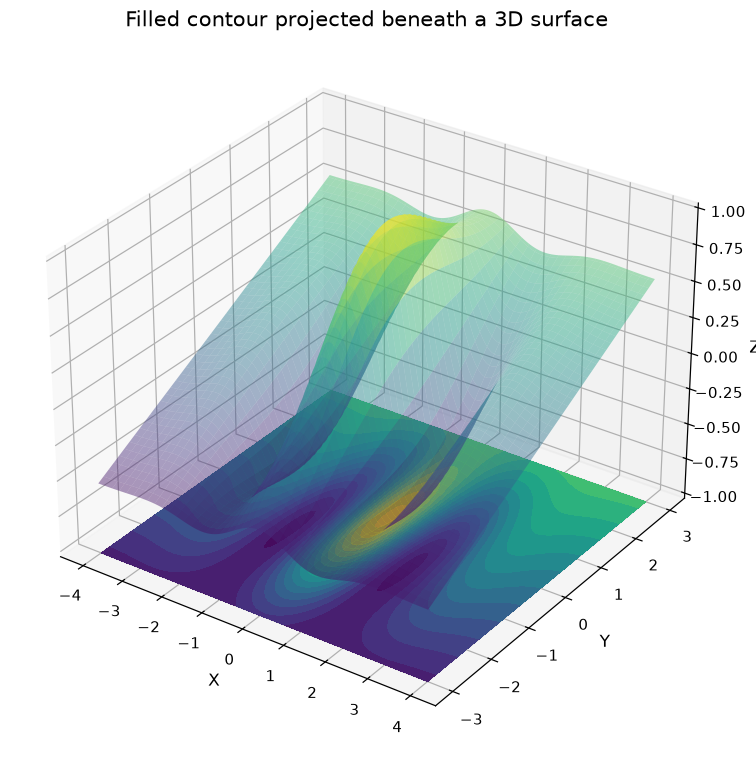

In [36]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(X, Y, Z, cmap="viridis", alpha=0.45, linewidth=0)
z_floor = Z.min() - 0.4
ax.contourf(X, Y, Z, zdir="z", offset=z_floor, levels=16, cmap="viridis")
ax.set_zlim(z_floor, Z.max())
ax.set(title="Filled contour projected beneath a 3D surface",
       xlabel="X", ylabel="Y", zlabel="Z")
ax.view_init(elev=30, azim=-55)
plt.tight_layout()
plt.show()


### 7.4 3D bar chart and 3D vector field

A 3D bar chart can encode three coordinates and bar height, but grouped 2D bars are often easier to compare. A 3D quiver plot uses arrows to show vector direction and magnitude.

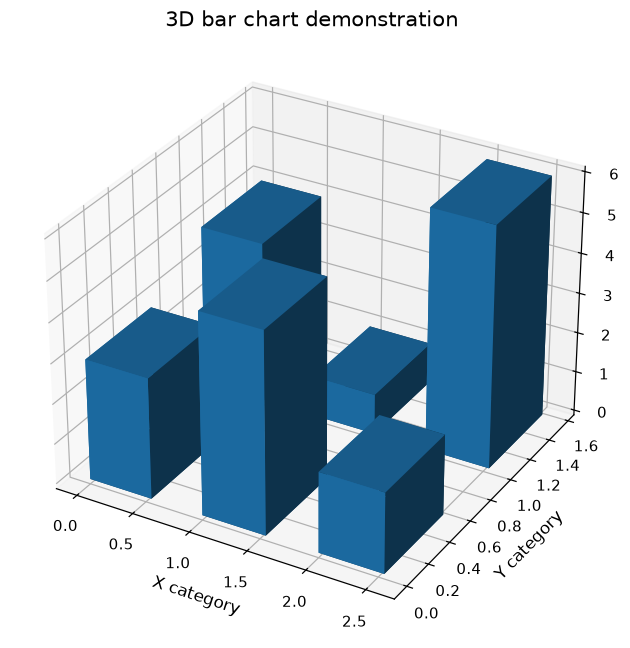

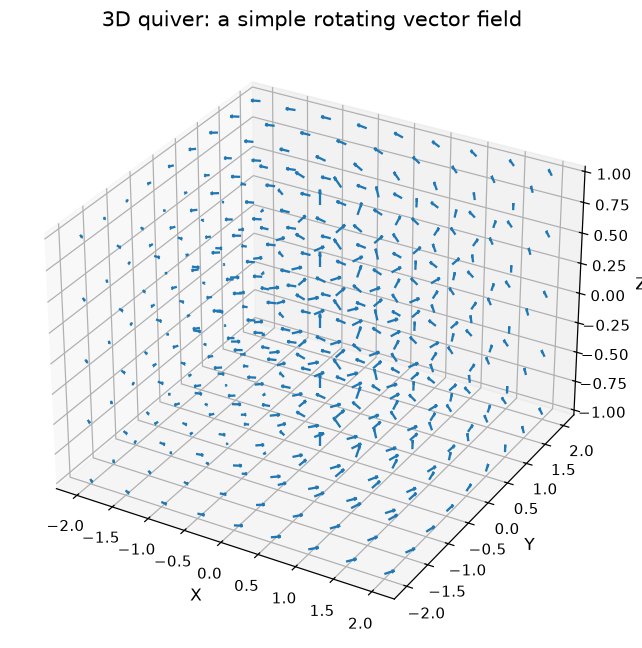

In [37]:
# 3D bars using a small, interpretable grid
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection="3d")
xpos = np.array([0, 1, 2, 0, 1, 2])
ypos = np.array([0, 0, 0, 1, 1, 1])
zpos = np.zeros_like(xpos)
dz = np.array([3, 5, 2, 4, 1, 6])
ax.bar3d(xpos, ypos, zpos, 0.55, 0.55, dz, shade=True)
ax.set(title="3D bar chart demonstration", xlabel="X category",
       ylabel="Y category", zlabel="Value")
plt.tight_layout()
plt.show()

# Vector field: arrows indicate direction and relative magnitude.
xs = np.linspace(-2, 2, 9)
ys = np.linspace(-2, 2, 9)
zs = np.linspace(-1, 1, 5)
XX, YY, ZZ = np.meshgrid(xs, ys, zs, indexing="ij")
U, V, W = -YY, XX, 0.35 * np.ones_like(ZZ)

fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection="3d")
ax.quiver(XX, YY, ZZ, U, V, W, length=0.12, normalize=True)
ax.set(title="3D quiver: a simple rotating vector field",
       xlabel="X", ylabel="Y", zlabel="Z")
plt.tight_layout()
plt.show()


## 8. Other useful Matplotlib plots

The Matplotlib API covers far more than line and scatter charts. These examples introduce several useful plot families:
- **Histogram:** distribution of a numeric variable.
- **Box plot:** median, quartiles, and potential outliers.
- **Violin plot:** a smoothed distribution shape.
- **Hexbin:** density for many overlapping points.
- **Error bars:** measurements with uncertainty.
- **Step plot:** piecewise-constant values.
- **Stack plot:** cumulative contributions over a shared x-axis.
- **Quiver/streamplot:** vector fields (usually 2D).
- **Triangular plots:** data sampled at irregular/unstructured coordinates (`tricontour`, `tripcolor`).

We'll use the penguin measurements for several of these.

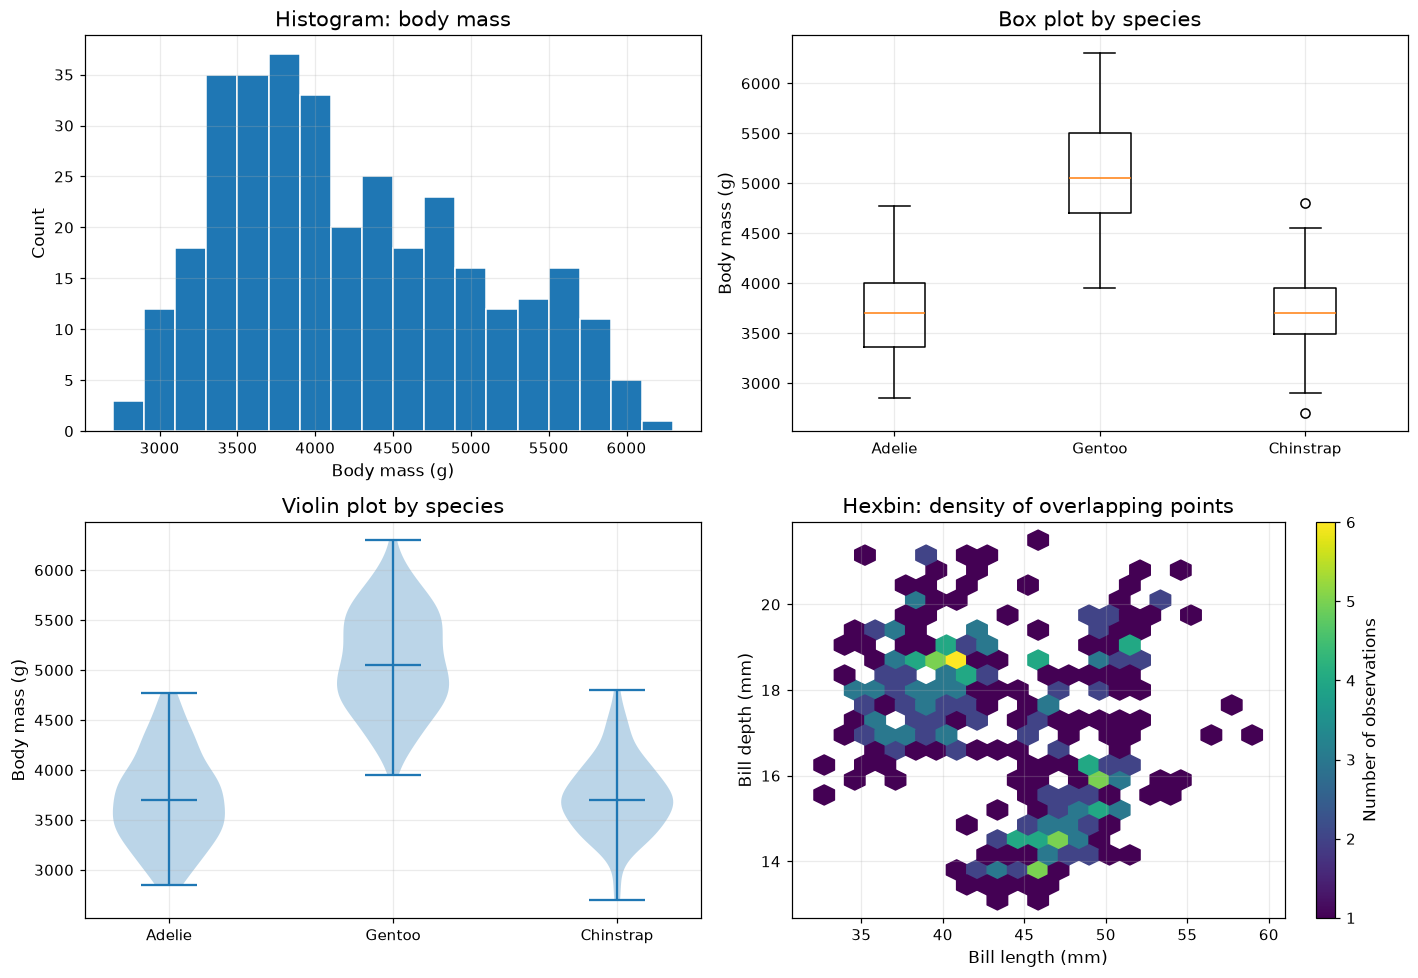

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0, 0].hist(plot_df["body_mass_g"], bins=18, edgecolor="white")
axes[0, 0].set(title="Histogram: body mass", xlabel="Body mass (g)", ylabel="Count")

mass_by_species = [
    plot_df.loc[plot_df["species"] == sp, "body_mass_g"].to_numpy()
    for sp in plot_df["species"].unique()
]
axes[0, 1].boxplot(mass_by_species, tick_labels=plot_df["species"].unique())
axes[0, 1].set(title="Box plot by species", ylabel="Body mass (g)")

axes[1, 0].violinplot(mass_by_species, showmedians=True, showextrema=True)
axes[1, 0].set_xticks(np.arange(1, len(mass_by_species)+1), plot_df["species"].unique())
axes[1, 0].set(title="Violin plot by species", ylabel="Body mass (g)")

hb = axes[1, 1].hexbin(plot_df["bill_length_mm"], plot_df["bill_depth_mm"],
                       gridsize=22, mincnt=1, cmap="viridis")
fig.colorbar(hb, ax=axes[1, 1], label="Number of observations")
axes[1, 1].set(title="Hexbin: density of overlapping points",
               xlabel="Bill length (mm)", ylabel="Bill depth (mm)")

fig.tight_layout()
plt.show()


### 8.1 Error bars and step plots

Error bars communicate uncertainty or variability when the meaning of the error value is stated. Step plots suit discrete states, counters, or piecewise-constant signals.

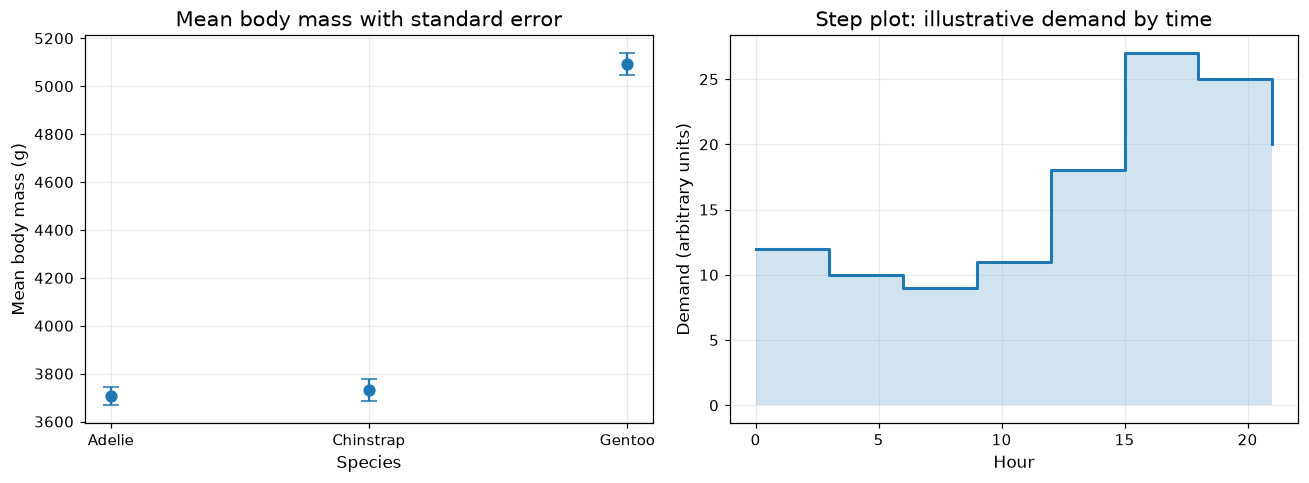

In [39]:
# Mean and standard error of body mass for each species
summary = plot_df.groupby("species", observed=True)["body_mass_g"].agg(["mean", "std", "count"])
summary["sem"] = summary["std"] / np.sqrt(summary["count"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].errorbar(summary.index, summary["mean"], yerr=summary["sem"],
                 fmt="o", capsize=5, markersize=7)
axes[0].set(title="Mean body mass with standard error",
            xlabel="Species", ylabel="Mean body mass (g)")

hours = np.arange(0, 24, 3)
demand = np.array([12, 10, 9, 11, 18, 27, 25, 20])
axes[1].step(hours, demand, where="post", linewidth=2)
axes[1].fill_between(hours, demand, step="post", alpha=0.2)
axes[1].set(title="Step plot: illustrative demand by time",
            xlabel="Hour", ylabel="Demand (arbitrary units)")
fig.tight_layout()
plt.show()


## 9. Formatting: ticks, grids, scales, and number formats

Ticks are the marks and labels on axes. Use major ticks for primary reference values and minor ticks for finer reading. Formatters change how values appear without changing the underlying data.

Useful tools:
- `MultipleLocator`: fixed interval between ticks.
- `AutoMinorLocator`: automatically subdivides major intervals.
- `FuncFormatter`: custom label formatting.
- `PercentFormatter`: show fractions as percentages.
- `set_xscale("log")` / `set_yscale("log")`: use logarithmic axes for suitable positive data.

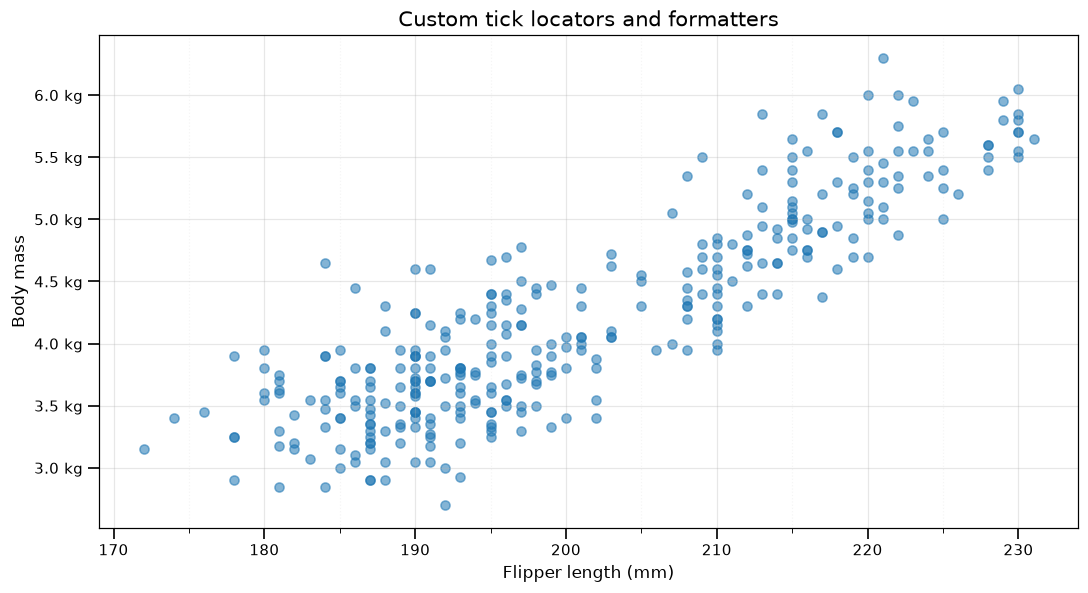

In [40]:
# Example: show body mass in kilograms, even though the stored data are grams.
fig, ax = plt.subplots()
ax.scatter(plot_df["flipper_length_mm"], plot_df["body_mass_g"], alpha=0.55)

ax.yaxis.set_major_formatter(FuncFormatter(lambda grams, pos: f"{grams/1000:.1f} kg"))
ax.xaxis.set_major_locator(MultipleLocator(10))
ax.xaxis.set_minor_locator(AutoMinorLocator(2))
ax.tick_params(axis="both", which="major", length=7, width=1.1)
ax.tick_params(axis="both", which="minor", length=3)
ax.grid(which="major", alpha=0.3)
ax.grid(which="minor", alpha=0.12, linestyle=":")
ax.set(title="Custom tick locators and formatters",
       xlabel="Flipper length (mm)", ylabel="Body mass")
fig.tight_layout()
plt.show()


### 9.1 Log scale and percentage formatting

A logarithmic scale is appropriate when values span orders of magnitude and are positive. It is not a default styling choice: explain why the scale is useful, and never apply it to zero/negative values without handling them first.

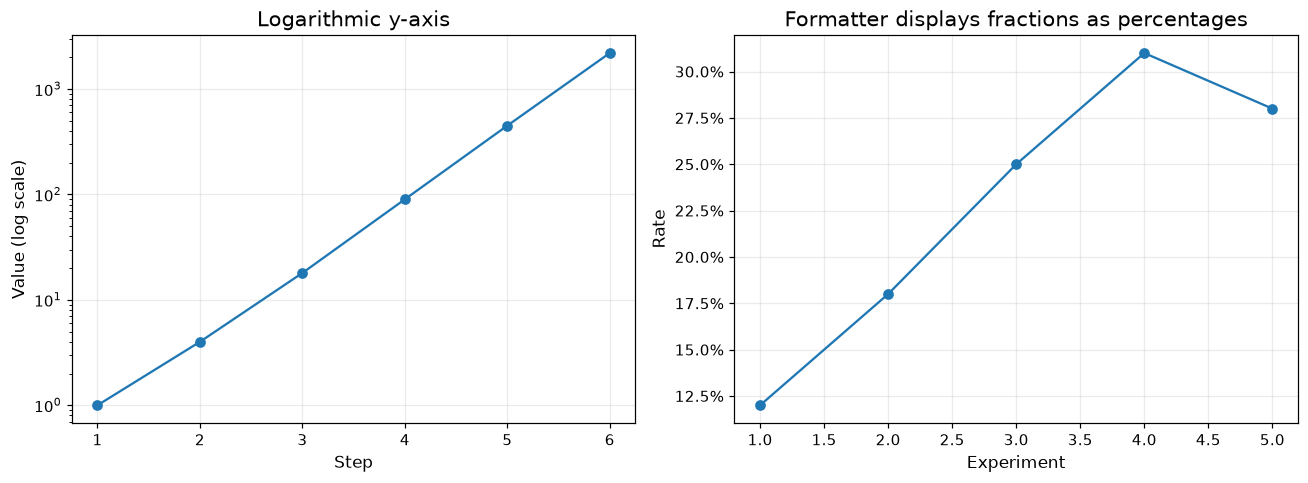

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

x = np.arange(1, 7)
values = np.array([1, 4, 18, 90, 450, 2200])
axes[0].plot(x, values, marker="o")
axes[0].set_yscale("log")
axes[0].set(title="Logarithmic y-axis", xlabel="Step", ylabel="Value (log scale)")

rates = np.array([0.12, 0.18, 0.25, 0.31, 0.28])
axes[1].plot(np.arange(1, 6), rates, marker="o")
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=1))
axes[1].set(title="Formatter displays fractions as percentages",
            xlabel="Experiment", ylabel="Rate")
fig.tight_layout()
plt.show()


## 10. Legends: clarity for multiple data series

Legends map visual encodings to meanings. Give plotted series meaningful `label=` values, use a descriptive legend title, and place the legend where it does not cover important data. For complex charts, custom legend handles let you explain encodings that are not themselves plotted as series.

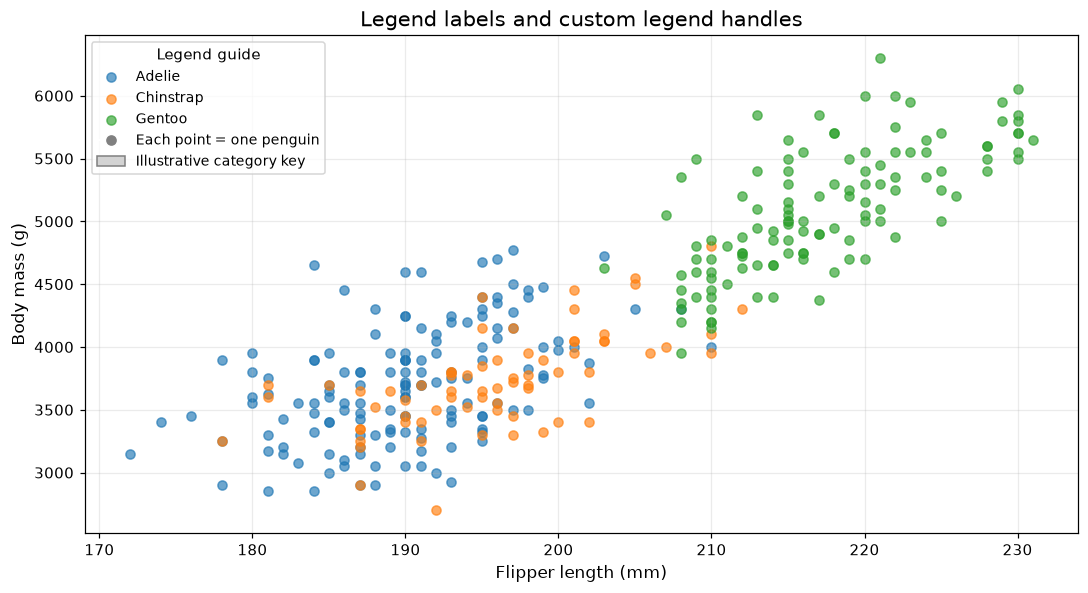

In [42]:
fig, ax = plt.subplots()
colors = {"Adelie": "tab:blue", "Chinstrap": "tab:orange", "Gentoo": "tab:green"}

for species, group in plot_df.groupby("species"):
    ax.scatter(group["flipper_length_mm"], group["body_mass_g"],
               color=colors.get(species), alpha=0.65, label=species)

# Custom handles can explain an additional visual convention.
custom_handles = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="gray",
           markersize=8, label="Each point = one penguin"),
    Patch(facecolor="lightgray", edgecolor="gray", label="Illustrative category key")
]
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles + custom_handles,
          labels=labels + [h.get_label() for h in custom_handles],
          title="Legend guide", loc="best", fontsize=9)
ax.set(title="Legend labels and custom legend handles",
       xlabel="Flipper length (mm)", ylabel="Body mass (g)")
fig.tight_layout()
plt.show()


## 11. Annotation, reference lines, and text placement

Use `ax.text()` to put text at data coordinates. Use `ax.annotate()` when a label should point to a particular observation. `ax.axhline()` and `ax.axvline()` add reference thresholds. Keep annotations selective—too many labels can obscure the data.

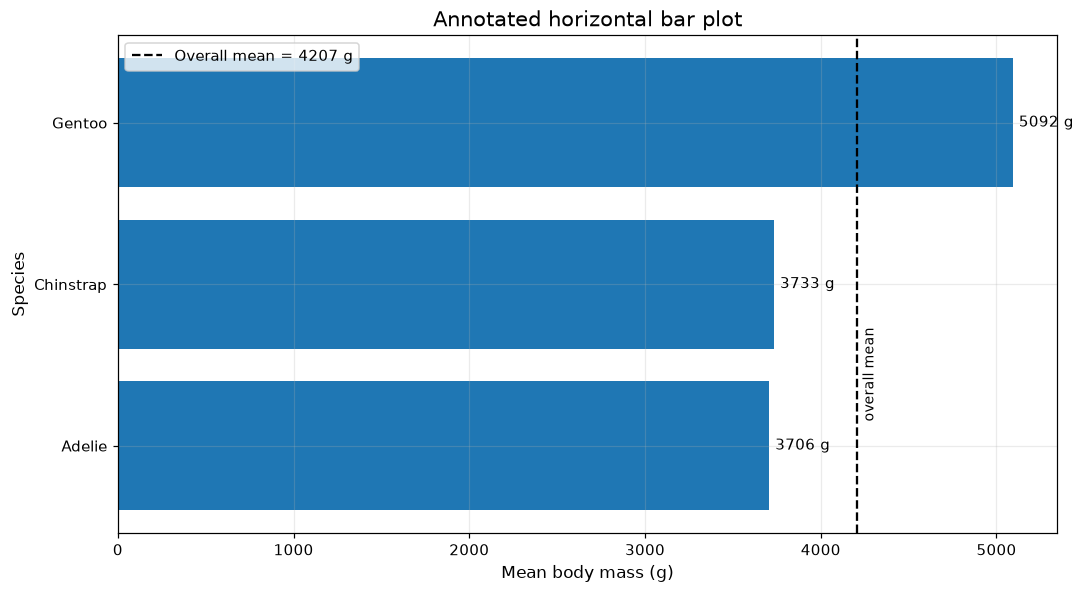

In [43]:
species_mean = plot_df.groupby("species", observed=True)["body_mass_g"].mean().sort_values()
fig, ax = plt.subplots()
bars = ax.barh(species_mean.index, species_mean.values)
ax.bar_label(bars, fmt="%.0f g", padding=4)
overall_mean = plot_df["body_mass_g"].mean()
ax.axvline(overall_mean, color="black", linestyle="--",
           label=f"Overall mean = {overall_mean:.0f} g")
ax.text(overall_mean + 30, 0.15, "overall mean",
        rotation=90, va="bottom", fontsize=9)
ax.set(title="Annotated horizontal bar plot",
       xlabel="Mean body mass (g)", ylabel="Species")
ax.legend()
fig.tight_layout()
plt.show()


## 12. Multi-panel figures and layout

Use multiple axes to compare different views of the same question. `subplots()` is a good starting point; `constrained_layout=True` often handles spacing automatically. For complicated dashboard-like layouts, explore `subplot_mosaic()` and `GridSpec`.

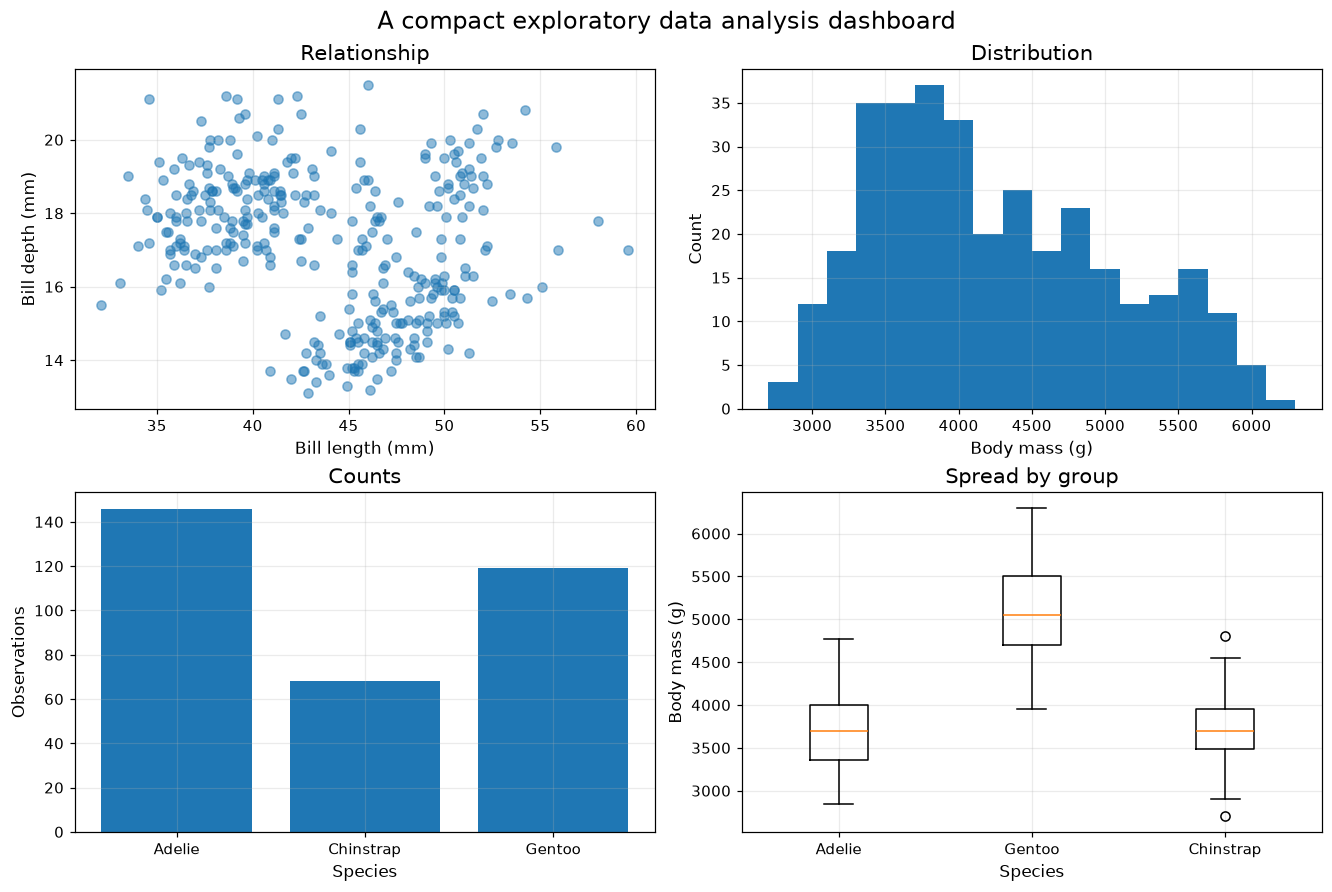

In [44]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)

axes[0, 0].scatter(plot_df["bill_length_mm"], plot_df["bill_depth_mm"], alpha=0.5)
axes[0, 0].set(title="Relationship", xlabel="Bill length (mm)", ylabel="Bill depth (mm)")

axes[0, 1].hist(plot_df["body_mass_g"], bins=18)
axes[0, 1].set(title="Distribution", xlabel="Body mass (g)", ylabel="Count")

axes[1, 0].bar(species_counts.index, species_counts.values)
axes[1, 0].set(title="Counts", xlabel="Species", ylabel="Observations")

axes[1, 1].boxplot(mass_by_species, tick_labels=plot_df["species"].unique())
axes[1, 1].set(title="Spread by group", xlabel="Species", ylabel="Body mass (g)")

fig.suptitle("A compact exploratory data analysis dashboard", fontsize=16)
plt.show()


## 13. Live weather data from Open-Meteo (API example)

**Problem statement:** How does the hourly temperature forecast evolve for a location?

This cell requests hourly forecast data from the public Open-Meteo API. The location is set to Kolkata as a teaching example; edit latitude and longitude to use another location. Forecasts are time-sensitive and should be interpreted as model output, not as verified observations. The request may fail in offline environments, so the code includes a synthetic fallback and clearly marks it.

API documentation: [Open-Meteo Forecast API](https://open-meteo.com/en/docs).

In [45]:
LATITUDE, LONGITUDE = 22.5726, 88.3639  # Kolkata example
weather_source = "Open-Meteo API"

try:
    response = requests.get(
        "https://api.open-meteo.com/v1/forecast",
        params={
            "latitude": LATITUDE,
            "longitude": LONGITUDE,
            "hourly": "temperature_2m,relative_humidity_2m,precipitation_probability",
            "forecast_days": 2,
            "timezone": "Asia/Kolkata",
        },
        timeout=20,
    )
    response.raise_for_status()
    payload = response.json()
    weather = pd.DataFrame(payload["hourly"])
    weather["time"] = pd.to_datetime(weather["time"])
    print("Loaded hourly forecast from Open-Meteo.")
except Exception as exc:
    print("Weather API request failed:", repr(exc))
    print("Using a clearly labelled synthetic fallback for plotting practice.")
    fallback_time = pd.date_range(pd.Timestamp.now().floor("h"), periods=48, freq="h")
    rng = np.random.default_rng(7)
    hour = np.arange(48)
    weather = pd.DataFrame({
        "time": fallback_time,
        "temperature_2m": 27 + 3*np.sin(2*np.pi*(hour-8)/24) + rng.normal(0, 0.4, 48),
        "relative_humidity_2m": np.clip(70 - 12*np.sin(2*np.pi*(hour-8)/24) + rng.normal(0, 2, 48), 30, 100),
        "precipitation_probability": np.clip(20 + 20*np.sin(2*np.pi*hour/24) + rng.normal(0, 8, 48), 0, 100),
    })
    weather_source = "Synthetic fallback (not real weather)"

display(weather.head())
print("Data source:", weather_source)


Loaded hourly forecast from Open-Meteo.


,time,temperature_2m,relative_humidity_2m,precipitation_probability
0,2026-10-27 00:00:00,27.4,69,0
1,2026-10-27 01:00:00,27.1,70,0
2,2026-10-27 02:00:00,26.8,70,0
3,2026-10-27 03:00:00,26.6,71,0
4,2026-10-27 04:00:00,26.3,72,0


Data source: Open-Meteo API


### 13.1 Plot temperature, humidity, and precipitation probability

This figure uses separate axes because the units differ. Avoid putting quantities with different units on the same y-axis without a clear rationale.

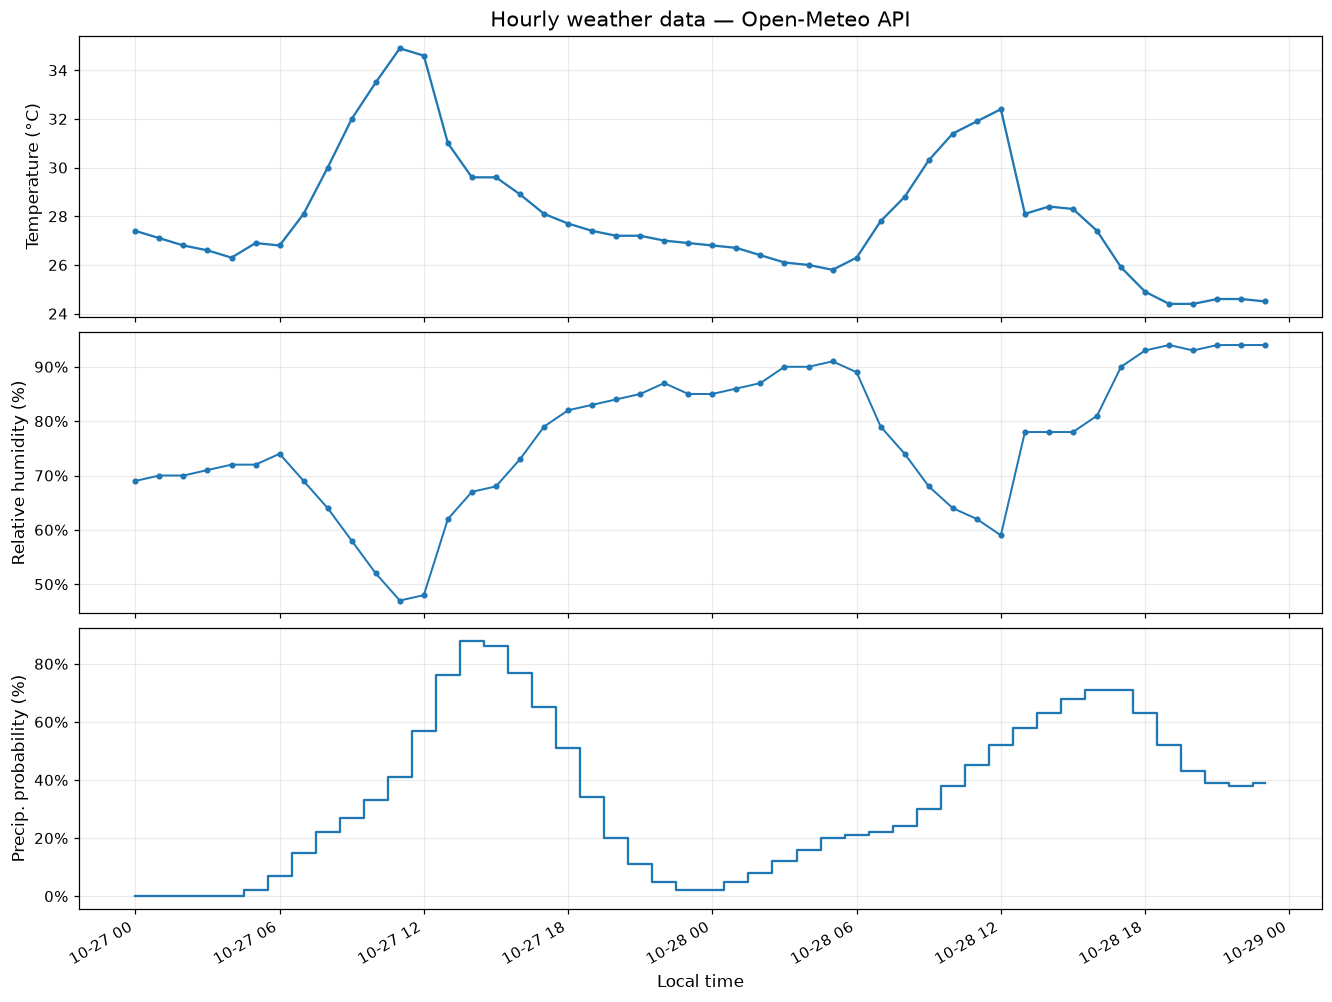

In [46]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, constrained_layout=True)

axes[0].plot(weather["time"], weather["temperature_2m"], marker=".", linewidth=1.5)
axes[0].set_ylabel("Temperature (°C)")
axes[0].set_title(f"Hourly weather data — {weather_source}")

axes[1].plot(weather["time"], weather["relative_humidity_2m"], marker=".", linewidth=1.3)
axes[1].set_ylabel("Relative humidity (%)")
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=100))

axes[2].step(weather["time"], weather["precipitation_probability"],
             where="mid", linewidth=1.5)
axes[2].set_ylabel("Precip. probability (%)")
axes[2].yaxis.set_major_formatter(PercentFormatter(xmax=100))
axes[2].set_xlabel("Local time")

for ax in axes:
    ax.grid(True, alpha=0.25)

fig.autofmt_xdate()
plt.show()


## 14. Saving figures for reports and presentations

For high-quality output, save directly from the `Figure` object. Use `dpi=300` for raster images in print workflows, or PDF/SVG for vector output where supported. `bbox_inches="tight"` trims excess margins.

The next cell creates a reusable figure and saves PNG and PDF versions into the notebook's current working directory.

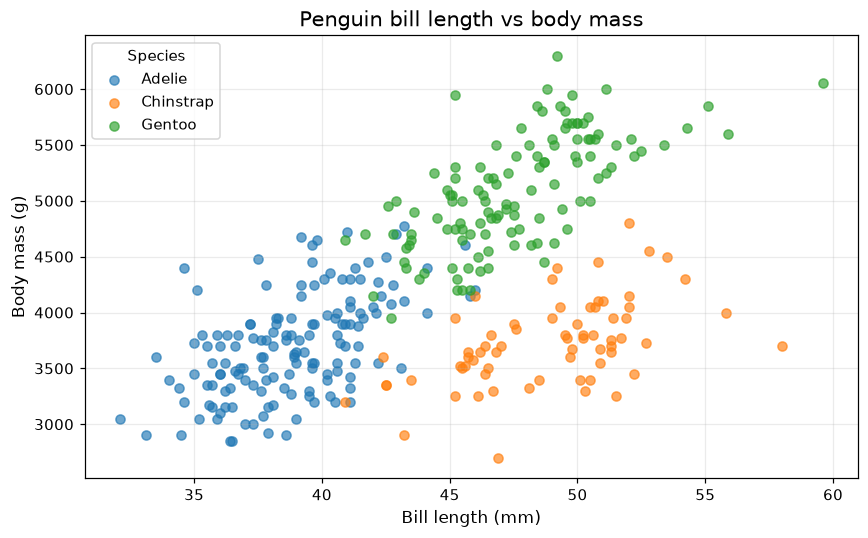

Saved penguin_scatter.png and penguin_scatter.pdf to the current working directory.


In [47]:
fig, ax = plt.subplots(figsize=(8, 5))
for species, group in plot_df.groupby("species"):
    ax.scatter(group["bill_length_mm"], group["body_mass_g"],
               alpha=0.65, label=species)
ax.set(title="Penguin bill length vs body mass",
       xlabel="Bill length (mm)", ylabel="Body mass (g)")
ax.legend(title="Species")
fig.tight_layout()

fig.savefig("penguin_scatter.png", dpi=300, bbox_inches="tight")
fig.savefig("penguin_scatter.pdf", bbox_inches="tight")
plt.show()
print("Saved penguin_scatter.png and penguin_scatter.pdf to the current working directory.")


## 15. Troubleshooting and good visualization practice

1. **A blank or distorted contour plot:** confirm `X`, `Y`, and `Z` have compatible shapes; for a meshgrid, `Z` is commonly 2D with the same shape as `X` and `Y`.
2. **Wrong pseudocolor orientation:** check `origin`, `extent`, and coordinate ordering. `imshow` treats the input as a raster; `pcolormesh` works with coordinate grids.
3. **3D plot looks too dense:** downsample the grid for a wireframe, reduce marker size, and adjust `view_init(elev=..., azim=...)`.
4. **Legend covers data:** move it outside with `bbox_to_anchor`, or simplify the figure.
5. **Ticks overlap:** rotate date labels, reduce tick count, use `fig.autofmt_xdate()`, or use a locator suited to the scale.
6. **Color is hard to interpret:** add a colorbar with a unit-bearing label; use perceptually uniform colormaps such as `viridis` for ordered values.
7. **Bar charts mislead:** start at zero for ordinary magnitude comparisons and state whether bars show counts, means, totals, or rates.
8. **Uncertainty is unclear:** specify whether error bars mean standard deviation, standard error, confidence interval, or measurement error.
9. **Dataset fetch fails:** check internet access, retry later, or download the CSV from the source page and load it locally.
10. **Version differences:** Matplotlib APIs evolve. If an argument is unsupported, check the installed version and the current API docs.

## 16. Student exercises

Try these independently, then compare results with a partner.

1. **Scatter:** color the penguin scatter plot by island. Add a title and a note explaining what each point represents.
2. **Bars:** plot median rather than mean body mass by species. Why might the median be useful?
3. **Fill:** generate two noisy signals and shade the region where signal A is greater than signal B.
4. **Contours:** change the mathematical field to `Z = sin(X) * cos(Y)`. Compare line contours with filled contours.
5. **Pseudocolor:** compare `pcolor` and `pcolormesh` on a non-uniform coordinate grid.
6. **3D projection:** move the projected contour to the `x` or `y` plane using `zdir="x"` or `zdir="y"` and a suitable `offset`.
7. **Formatting:** format the x-axis as dates and choose a sensible date locator for the weather data.
8. **Legend:** place the legend outside the axes without clipping it when saving.
9. **Live-data critique:** rerun the Open-Meteo cell later. What changed? Which values are forecasts rather than observations?
10. **Communication:** choose one plot and write a two-sentence interpretation that distinguishes what the plot shows from what it cannot prove.

### Challenge: mini visualization report
Choose a question, document your dataset source and retrieval date, clean the data, create at least three complementary plots, and write 4–6 findings. Include units, legends, and a short limitations section.

## 17. Documentation and further reading

Use the official documentation to look up parameters and explore examples. These links are the starting points for the plot types demonstrated here.

- [Matplotlib plot types overview](https://matplotlib.org/stable/plot_types/index.html) — chart selection and API overview.
- [Matplotlib gallery](https://matplotlib.org/stable/gallery/) — runnable examples grouped by topic.
- [mplot3d toolkit guide](https://matplotlib.org/stable/users/explain/toolkits/mplot3d.html) — 3D axes, scatter, surface, wireframe, and contour.
- [Pyplot summary](https://matplotlib.org/stable/api/pyplot_summary.html) — plot function index.
- [Legend guide](https://matplotlib.org/stable/users/explain/axes/legend_guide.html) — legend placement and custom handles.
- [Annotations guide](https://matplotlib.org/stable/users/explain/text/annotations.html) — annotation coordinates and arrows.
- [Ticker API](https://matplotlib.org/stable/api/ticker_api.html) — locators and formatters.
- [Colormap guidance](https://matplotlib.org/stable/users/explain/colors/colormaps.html) — choosing a colormap.
- [Palmer Penguins dataset](https://github.com/allisonhorst/palmerpenguins) — public ecological dataset.
- [Open-Meteo API documentation](https://open-meteo.com/en/docs) — hourly weather forecast endpoint.

**Instructor note:** Ask students to explain *why* a chart type fits the question, not merely to reproduce the code. A beautiful chart that obscures units, uncertainty, or data provenance is not a successful data visualization.